# Compare ISTARI GOI vs PDL Free Company Dataset
## Checking whether PDL's dataset can serve as the open-source substitute for a companion paper

**What this notebook does:**

Compares Istari's proprietary GOI (via the random, query-independent 300K sample) against People Data Labs' Free Company Dataset, to check field-schema compatibility, company overlap by domain/website, and distributional similarity (country, size, industry). The goal is evidence for or against using PDL as the open-source dataset for a scientific paper derived from this thesis's methodology.

**Inputs:**
- `dataset/goi_random_sample_300k_clean.parquet` (Istari side, 300,000 companies, random and query-independent)
- `dataset/pdl_companies/free_company_dataset.json` (PDL side, ~35.8 million companies, JSON-lines, ~10.7GB)

**Runtime note:** the PDL file is large and is streamed line-by-line rather than loaded into memory at once. Expect roughly 10-20 minutes depending on disk speed, this is I/O-bound, not compute-heavy.

**Output:** `result/comparison_summary.json` plus PNG figures in `result/`, all of which feed directly into the slide deck.

### Notebook structure
1. Environment setup
2. Load GOI random sample
3. Schema comparison
4. Stream PDL dataset (domain/website set, country counts, size counts, industry counts)
5. Build GOI-side comparison stats
6. Domain/website overlap
7. Country distribution comparison
8. Organisation size bucket comparison (approximate, buckets do not line up exactly)
9. Industry/NACE comparison (descriptive only, not a shared taxonomy)
10. The critical gap: does PDL have a free-text description field at all?
11. Where the overlap concentrates: overlap rate by country, industry, and size
12. Save consolidated summary

## 1 · Environment Setup

In [1]:
import json, re, time
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

DATASET_DIR = Path('../dataset')
RESULT_DIR = Path('result')
RESULT_DIR.mkdir(parents=True, exist_ok=True)

GOI_SAMPLE_PATH = DATASET_DIR / 'goi_random_sample_300k_clean.parquet'
PDL_PATH = DATASET_DIR / 'pdl_companies' / 'free_company_dataset.json'

print(f'[Setup] GOI sample path : {GOI_SAMPLE_PATH} (exists: {GOI_SAMPLE_PATH.exists()})')
print(f'[Setup] PDL path        : {PDL_PATH} (exists: {PDL_PATH.exists()})')

[Setup] GOI sample path : ../dataset/goi_random_sample_300k_clean.parquet (exists: True)
[Setup] PDL path        : ../dataset/pdl_companies/free_company_dataset.json (exists: True)


## 2 · Load GOI Random Sample

Using the random, query-independent 300K sample rather than the query-derived corpus, so the comparison reflects the GOI's overall composition rather than a search-query-skewed subset.

In [2]:
goi_df = pd.read_parquet(GOI_SAMPLE_PATH)
print(f'[Load] GOI sample rows   : {len(goi_df):,}')
print(f'[Load] GOI sample fields : {goi_df.columns.tolist()}')
goi_df.head(3)

[Load] GOI sample rows   : 300,000
[Load] GOI sample fields : ['domain', 'name', 'organization_type', 'organization_size', 'country', 'state', 'district', 'municipality', 'summary', 'summary_keywords', 'nace_code', 'already_in_existing_corpus', 'has_duplicate_summary']


,domain,name,organization_type,organization_size,country,state,district,municipality,summary,summary_keywords,nace_code,already_in_existing_corpus,has_duplicate_summary
0,nzemlya.com,Новая Земля,Company,Medium-sized (50-249),Russia,Yevrey,None,None,Новая Земля is a company specializing in urban...,"[""urban planning"", ""master planning"", ""city de...","NACE N: Professional, scientific and technical...",False,False
1,cedarsidinginc.com,"Cedar Siding, Inc.",Company,Micro (0-9),United States,None,None,None,"Cedar Siding, Inc. is a company with over 20 y...","[""siding"", ""building materials"", ""factory fini...",NACE G: Wholesale and retail trade,False,False
2,nexthype.ch,Next Hype,Company,Small (10-49),Switzerland,Zürich,Dübendorf,None,Next Hype is a creative agency specializing in...,"[""3D content"", ""Immersive campaigns"", ""Creativ...","NACE N: Professional, scientific and technical...",False,False


## 3 · Schema Comparison

Manual field mapping between the two schemas, based on inspecting both datasets directly. This table is the first thing that goes into the slide deck.

In [3]:
schema_map = [
    {'goi_field': 'domain',            'pdl_field': 'website',      'note': 'direct match, used as the join key for overlap'},
    {'goi_field': 'name',              'pdl_field': 'name',         'note': 'direct match'},
    {'goi_field': 'country',           'pdl_field': 'country',      'note': 'direct match'},
    {'goi_field': 'state',             'pdl_field': 'region',       'note': 'approximate match, granularity may differ'},
    {'goi_field': 'district/municipality', 'pdl_field': 'locality', 'note': 'GOI has two finer levels, PDL has one'},
    {'goi_field': 'organization_size', 'pdl_field': 'size',         'note': 'both bucketed, but bucket boundaries differ, see Section 8'},
    {'goi_field': 'nace_code',         'pdl_field': 'industry',     'note': 'different taxonomies entirely, NACE vs free-text/LinkedIn-style category, see Section 9'},
    {'goi_field': 'organization_type', 'pdl_field': None,           'note': 'no PDL equivalent'},
    {'goi_field': None,                'pdl_field': 'founded',      'note': 'no GOI equivalent'},
    {'goi_field': None,                'pdl_field': 'linkedin_url', 'note': 'no GOI equivalent'},
    {'goi_field': 'summary',           'pdl_field': None,           'note': 'CRITICAL: PDL has no free-text company description field at all, see Section 10'},
    {'goi_field': 'summary_keywords',  'pdl_field': None,           'note': 'CRITICAL: derived from summary, same gap'},
]
schema_df = pd.DataFrame(schema_map)
schema_df.to_csv(RESULT_DIR / 'schema_comparison.csv', index=False)
schema_df

,goi_field,pdl_field,note
0,domain,website,"direct match, used as the join key for overlap"
1,name,name,direct match
2,country,country,direct match
3,state,region,"approximate match, granularity may differ"
4,district/municipality,locality,"GOI has two finer levels, PDL has one"
5,organization_size,size,"both bucketed, but bucket boundaries differ, s..."
6,nace_code,industry,"different taxonomies entirely, NACE vs free-te..."
7,organization_type,None,no PDL equivalent
8,None,founded,no GOI equivalent
9,None,linkedin_url,no GOI equivalent


## 4 · Stream PDL Dataset

The PDL file is ~35.8 million lines and ~10.7GB, so this reads it line by line rather than loading it into a DataFrame. Only the fields needed for comparison are kept in memory (normalised domains, and counters for country/size/industry), not full records.

In [4]:
def normalise_domain(raw):
    if not raw:
        return None
    d = raw.strip().lower()
    d = re.sub(r'^https?://', '', d)
    d = re.sub(r'^www\.', '', d)
    d = d.split('/')[0]
    d = d.strip()
    return d if d else None

In [5]:
pdl_domains = set()
pdl_country_counts = Counter()
pdl_size_counts = Counter()
pdl_industry_counts = Counter()
pdl_has_description_field = False
pdl_total_rows = 0
pdl_parse_errors = 0

PROGRESS_EVERY = 5_000_000
t0 = time.time()

with open(PDL_PATH, 'r', encoding='utf-8') as f:
    for i, line in enumerate(f):
        pdl_total_rows += 1
        try:
            rec = json.loads(line)
        except json.JSONDecodeError:
            pdl_parse_errors += 1
            continue
        dom = normalise_domain(rec.get('website'))
        if dom:
            pdl_domains.add(dom)
        if rec.get('country'):
            pdl_country_counts[rec['country']] += 1
        if rec.get('size'):
            pdl_size_counts[rec['size']] += 1
        if rec.get('industry'):
            pdl_industry_counts[rec['industry']] += 1
        if i == 0:
            pdl_has_description_field = any(k in rec for k in ('description', 'summary', 'about'))
            print(f'[Schema check] first PDL record keys: {sorted(rec.keys())}')
        if (i + 1) % PROGRESS_EVERY == 0:
            elapsed = time.time() - t0
            print(f'[Stream] {i+1:,} rows processed, {elapsed:.0f}s elapsed, {len(pdl_domains):,} unique domains so far')

elapsed = time.time() - t0
print('-' * 55)
print(f'[Stream] Done! {pdl_total_rows:,} total rows, {pdl_parse_errors:,} parse errors, {elapsed:.0f}s elapsed')
print(f'[Stream] Unique PDL domains : {len(pdl_domains):,}')
print(f'[Stream] Has a description/summary/about field: {pdl_has_description_field}')

[Schema check] first PDL record keys: ['country', 'founded', 'id', 'industry', 'linkedin_url', 'locality', 'name', 'region', 'size', 'website']


[Stream] 5,000,000 rows processed, 37s elapsed, 3,221,239 unique domains so far
[Stream] 10,000,000 rows processed, 74s elapsed, 6,442,766 unique domains so far
[Stream] 15,000,000 rows processed, 111s elapsed, 9,663,169 unique domains so far
[Stream] 20,000,000 rows processed, 148s elapsed, 12,882,952 unique domains so far
[Stream] 25,000,000 rows processed, 185s elapsed, 16,103,785 unique domains so far
[Stream] 30,000,000 rows processed, 223s elapsed, 19,324,068 unique domains so far
[Stream] 35,000,000 rows processed, 262s elapsed, 22,545,100 unique domains so far
-------------------------------------------------------
[Stream] Done! 35,828,989 total rows, 0 parse errors, 268s elapsed
[Stream] Unique PDL domains : 23,079,155
[Stream] Has a description/summary/about field: False


## 5 · GOI-Side Comparison Stats

In [6]:
goi_domains = set(goi_df['domain'].dropna().apply(normalise_domain).dropna())
goi_country_counts = Counter(goi_df['country'].dropna())
goi_size_counts = Counter(goi_df['organization_size'].dropna())

def nace_section(raw):
    if not raw:
        return None
    m = re.match(r'NACE\s+([A-Z]):', raw)
    return f'NACE {m.group(1)}' if m else raw

goi_nace_counts = Counter(goi_df['nace_code'].dropna().apply(nace_section))

print(f'[GOI] Unique domains          : {len(goi_domains):,}')
print(f'[GOI] Distinct countries      : {len(goi_country_counts):,}')
print(f'[GOI] Distinct size buckets   : {len(goi_size_counts):,} -> {dict(goi_size_counts)}')
print(f'[GOI] Distinct NACE sections  : {len(goi_nace_counts):,}')

[GOI] Unique domains          : 300,000
[GOI] Distinct countries      : 198
[GOI] Distinct size buckets   : 4 -> {'Medium-sized (50-249)': 26496, 'Micro (0-9)': 128597, 'Small (10-49)': 132366, 'Large enterprise (250+)': 12523}
[GOI] Distinct NACE sections  : 21


## 6 · Domain/Website Overlap

This is the single strongest piece of evidence for similarity: what fraction of the GOI's companies are also present in PDL's free dataset, matched by normalised domain.

In [7]:
overlap = goi_domains & pdl_domains
overlap_pct_of_goi = 100 * len(overlap) / len(goi_domains) if goi_domains else 0.0
overlap_pct_of_pdl = 100 * len(overlap) / len(pdl_domains) if pdl_domains else 0.0

print(f'[Overlap] GOI sample domains       : {len(goi_domains):,}')
print(f'[Overlap] PDL domains              : {len(pdl_domains):,}')
print(f'[Overlap] Domains in both          : {len(overlap):,}')
print(f'[Overlap] Share of GOI sample covered by PDL : {overlap_pct_of_goi:.1f}%')
print(f'[Overlap] Share of PDL covered by GOI sample : {overlap_pct_of_pdl:.2f}%')

[Overlap] GOI sample domains       : 300,000
[Overlap] PDL domains              : 23,079,155
[Overlap] Domains in both          : 121,300
[Overlap] Share of GOI sample covered by PDL : 40.4%
[Overlap] Share of PDL covered by GOI sample : 0.53%


## 7 · Country Distribution Comparison

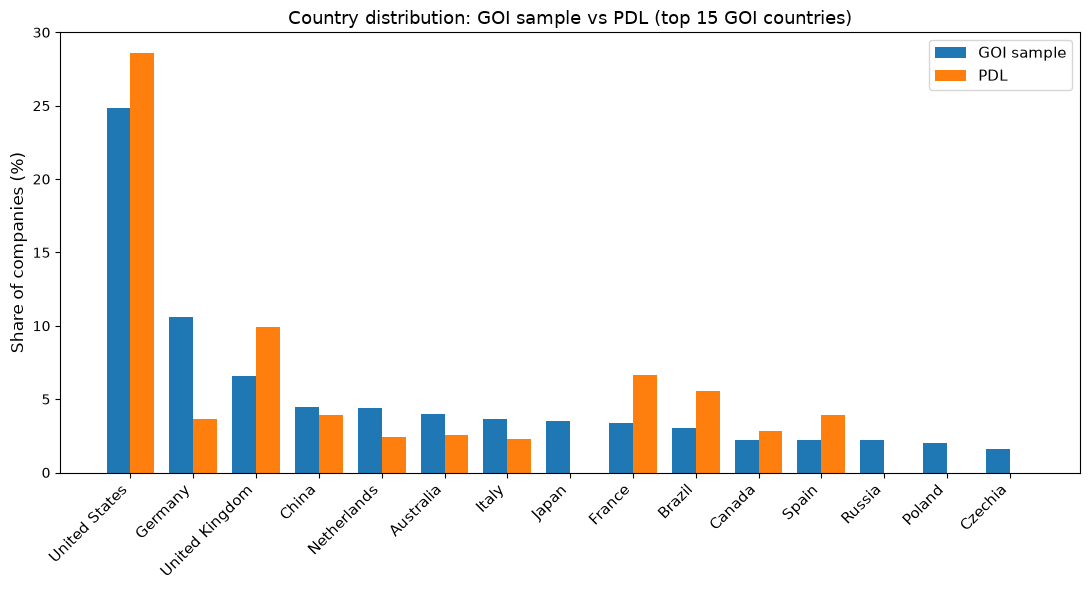

In [13]:
def top_share(counter, n=15):
    total = sum(counter.values())
    top = counter.most_common(n)
    return {k: 100 * v / total for k, v in top}

# PDL stores country names lower-case ('india'), GOI uses Title Case ('India'), normalise both to Title Case before comparing
goi_country_counts_norm = Counter({k.title(): v for k, v in goi_country_counts.items()})
pdl_country_counts_norm = Counter()
for k, v in pdl_country_counts.items():
    pdl_country_counts_norm[k.title()] += v

goi_country_share = top_share(goi_country_counts_norm)
pdl_country_share = top_share(pdl_country_counts_norm)

countries = sorted(set(goi_country_share) | set(pdl_country_share), key=lambda c: -goi_country_share.get(c, 0))[:15]
goi_vals = [goi_country_share.get(c, 0) for c in countries]
pdl_vals = [pdl_country_share.get(c, 0) for c in countries]

fig, ax = plt.subplots(figsize=(11, 6))
x = range(len(countries))
width = 0.38
ax.bar([i - width/2 for i in x], goi_vals, width, label='GOI sample')
ax.bar([i + width/2 for i in x], pdl_vals, width, label='PDL')
ax.set_xticks(list(x))
ax.set_xticklabels(countries, rotation=45, ha='right', fontsize=11)
ax.set_ylabel('Share of companies (%)', fontsize=12)
ax.set_title('Country distribution: GOI sample vs PDL (top 15 GOI countries)', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'country_distribution_comparison.png', dpi=150)
plt.show()

## 8 · Organisation Size Bucket Comparison

GOI uses EU SME-style buckets (Micro/Small/Medium-sized/Large enterprise), PDL uses LinkedIn-style numeric-range buckets. These do not align exactly, the mapping below is approximate and should be read as descriptive, not a precise crosswalk.

In [14]:
print('[GOI size buckets]')
for k, v in goi_size_counts.most_common():
    print(f'  {k:30s} {v:>8,}')
print()
print('[PDL size buckets]')
for k, v in pdl_size_counts.most_common():
    print(f'  {k:30s} {v:>8,}')

[GOI size buckets]
  Small (10-49)                   132,366
  Micro (0-9)                     128,597
  Medium-sized (50-249)            26,496
  Large enterprise (250+)          12,523

[PDL size buckets]
  1-10                           28,046,086
  11-50                          5,240,052
  51-200                         1,586,032
  201-500                         539,457
  501-1000                        180,108
  1001-5000                       151,645
  10001+                           52,848
  5001-10000                       32,761


## 9 · Industry Comparison (descriptive only)

NACE and PDL's industry field are different taxonomies entirely, NACE is a structured EU statistical classification, PDL's `industry` field looks like free-text/LinkedIn-style category labels. This section just lists the top categories from each side side by side, it is not a like-for-like comparison.

In [15]:
print('[GOI top NACE sections]')
for k, v in goi_nace_counts.most_common(10):
    print(f'  {k:10s} {v:>8,}')
print()
print('[PDL top industry labels]')
for k, v in pdl_industry_counts.most_common(10):
    print(f'  {k:40s} {v:>8,}')

[GOI top NACE sections]
  NACE N       54,407
  NACE G       39,477
  NACE C       35,366
  NACE R       25,225
  NACE F       20,667
  NACE K       20,067
  NACE I       19,806
  NACE S       19,204
  NACE Q       10,297
  NACE J        9,903

[PDL top industry labels]
  construction                             1,444,035
  information technology and services      1,399,005
  retail                                   1,250,997
  management consulting                    1,196,975
  real estate                              1,031,450
  marketing and advertising                1,022,590
  computer software                         855,524
  restaurants                               759,289
  medical practice                          739,586
  internet                                  598,285


## 10 · The Critical Gap: Does PDL Have a Free-Text Description Field?

This thesis's entire retrieval approach depends on the `summary` field, an AI-generated natural-language description of each company, it is the single most important field in the GOI schema for this task. If PDL has no equivalent, it cannot directly substitute for GOI in a semantic-retrieval paper without first generating descriptions some other way (e.g. scraping company websites), which is a real added cost worth surfacing before committing to PDL.

In [16]:
print(f'[Critical check] PDL record keys observed: sorted(rec.keys()) printed above in Section 4')
print(f'[Critical check] Does PDL have a description/summary/about field: {pdl_has_description_field}')
if not pdl_has_description_field:
    print('[Critical check] PDL has NO free-text company description field.')
    print('[Critical check] Using PDL as-is would require sourcing descriptions separately (e.g. website scraping) before it could support the same embedding-based retrieval task.')

[Critical check] PDL record keys observed: sorted(rec.keys()) printed above in Section 4
[Critical check] Does PDL have a description/summary/about field: False
[Critical check] PDL has NO free-text company description field.
[Critical check] Using PDL as-is would require sourcing descriptions separately (e.g. website scraping) before it could support the same embedding-based retrieval task.


## 11 · Where Does the Overlap Concentrate?

Raw overlap (40.4%) is a blunt number. Checking the overlap **rate** per country, industry, and size, rather than just the raw count, shows whether PDL is a uniformly good substitute for GOI or only a strong substitute for certain slices of it.

In [18]:
goi_df['norm_domain'] = goi_df['domain'].apply(normalise_domain)
goi_df['in_pdl'] = goi_df['norm_domain'].isin(pdl_domains)

sanity_count = int(goi_df['in_pdl'].sum())
sanity_pct = 100 * sanity_count / len(goi_df)
print(f'[Sanity check] Companies flagged in_pdl: {sanity_count:,} ({sanity_pct:.2f}%)')
print(f'[Sanity check] Should match Section 6 overlap: 121,300 (40.43%)')

[Sanity check] Companies flagged in_pdl: 121,300 (40.43%)
[Sanity check] Should match Section 6 overlap: 121,300 (40.43%)


### Overlap rate by country

Only countries with at least 300 companies in the GOI sample are included, to avoid noisy rates from tiny samples.

[Country overlap] 56 countries have at least 300 GOI companies in the sample

[Top 10 overlap rate]
                           mean  count
country                               
Brazil                66.386555   9044
United Arab Emirates  64.681725    487
Colombia              64.482759    870
India                 61.947880   4528
Canada                56.260260   6701
Portugal              53.074205   1415
United States         52.592364  74623
Argentina             52.502453   1019
Indonesia             52.144082    583
United Kingdom        51.309457  19741

[Bottom 10 overlap rate]
                  mean  count
country                      
Slovenia     18.166667    600
Taiwan       17.482517    858
Ukraine      16.120577    763
Czechia      15.355805   4806
South Korea  13.160920   1740
Slovakia     11.857437   1459
China        11.270858  13424
Japan         8.376914  10517
Belarus       6.764706    340
Russia        6.426618   6582


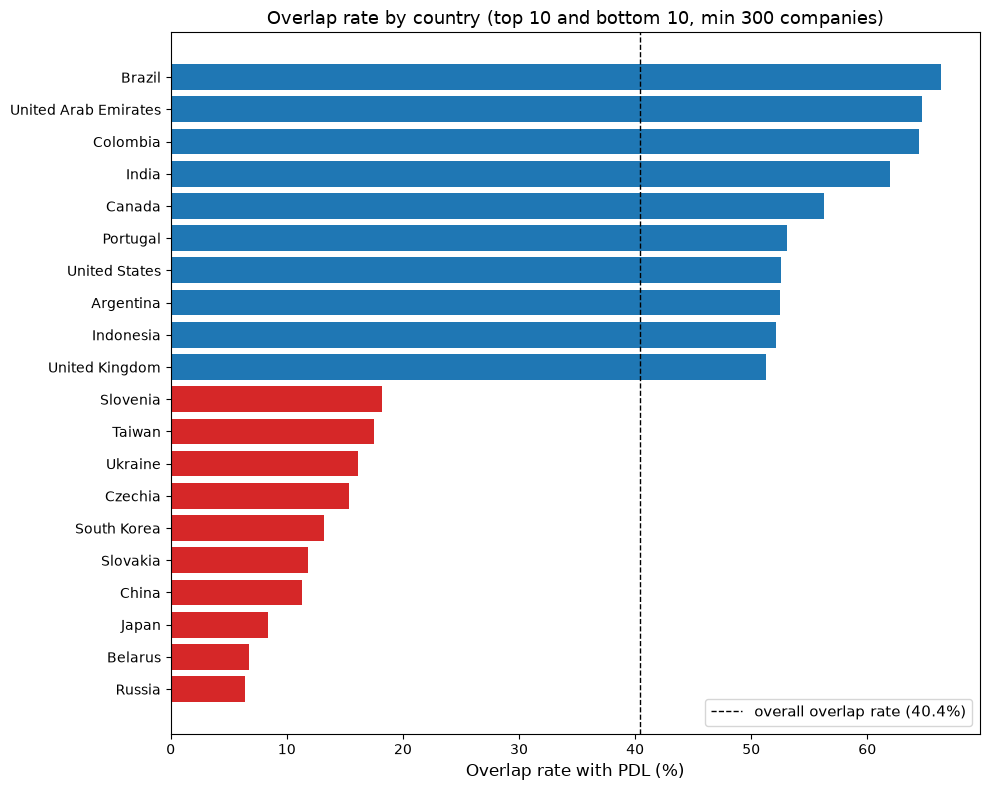

In [19]:
MIN_COUNTRY_N = 300

country_overlap = goi_df.groupby('country')['in_pdl'].agg(['mean', 'count'])
country_overlap['mean'] = 100 * country_overlap['mean']
country_overlap = country_overlap[country_overlap['count'] >= MIN_COUNTRY_N].sort_values('mean', ascending=False)

print(f'[Country overlap] {len(country_overlap)} countries have at least {MIN_COUNTRY_N} GOI companies in the sample')
print()
print('[Top 10 overlap rate]')
print(country_overlap.head(10).to_string())
print()
print('[Bottom 10 overlap rate]')
print(country_overlap.tail(10).to_string())

top_bottom = pd.concat([country_overlap.head(10), country_overlap.tail(10)])
fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#1f77b4' if v >= 40.43 else '#d62728' for v in top_bottom['mean']]
ax.barh(top_bottom.index[::-1], top_bottom['mean'][::-1], color=colors[::-1])
ax.axvline(40.43, color='black', linestyle='--', linewidth=1, label='overall overlap rate (40.4%)')
ax.set_xlabel('Overlap rate with PDL (%)', fontsize=12)
ax.set_title(f'Overlap rate by country (top 10 and bottom 10, min {MIN_COUNTRY_N} companies)', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'overlap_rate_by_country.png', dpi=150)
plt.show()

### Overlap rate by industry (NACE section)

Uses GOI's own NACE section, since PDL's industry labels are a different taxonomy entirely (Section 9). This checks whether certain industries are better represented in PDL than others, independent of what PDL calls them.

[NACE section overlap rate, all sections]
                   mean  count
nace_section                  
NACE L        54.884280   6654
NACE B        54.682779    331
NACE D        50.080775    619
NACE N        48.161082  54407
NACE Q        47.373021  10297
NACE K        47.226790  20067
NACE H        41.794548   5539
NACE C        41.571000  35366
NACE P        41.451209   2398
NACE O        41.248470   7353
NACE R        40.911794  25225
NACE M        39.905067   9059
NACE E        37.577465   1775
NACE G        36.803708  39477
NACE F        36.560701  20667
NACE U        33.333333      3
NACE I        33.040493  19806
NACE A        31.881592   2939
NACE J        31.152176   9903
NACE S        30.441575  19204
NACE T        27.504779   8893


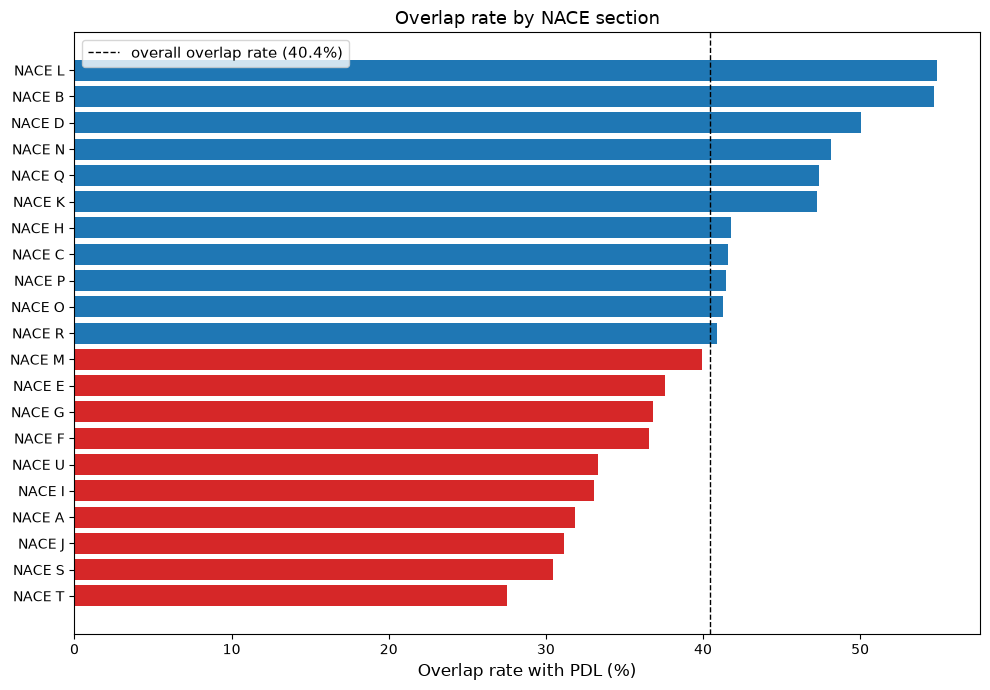

In [20]:
goi_df['nace_section'] = goi_df['nace_code'].apply(nace_section)

nace_overlap = goi_df.groupby('nace_section')['in_pdl'].agg(['mean', 'count'])
nace_overlap['mean'] = 100 * nace_overlap['mean']
nace_overlap = nace_overlap.sort_values('mean', ascending=False)

print('[NACE section overlap rate, all sections]')
print(nace_overlap.to_string())

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#1f77b4' if v >= 40.43 else '#d62728' for v in nace_overlap['mean']]
ax.barh(nace_overlap.index[::-1], nace_overlap['mean'][::-1], color=colors[::-1])
ax.axvline(40.43, color='black', linestyle='--', linewidth=1, label='overall overlap rate (40.4%)')
ax.set_xlabel('Overlap rate with PDL (%)', fontsize=12)
ax.set_title('Overlap rate by NACE section', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'overlap_rate_by_nace.png', dpi=150)
plt.show()

### Overlap rate by organisation size

[Overlap rate by organisation size]
                              mean   count
organization_size                         
Micro (0-9)              29.874725  128597
Small (10-49)            47.327864  132366
Medium-sized (50-249)    53.291063   26496
Large enterprise (250+)  48.766270   12523


/scratch/ipykernel_2230040/2059614484.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(size_overlap.index, rotation=20, ha='right', fontsize=10)


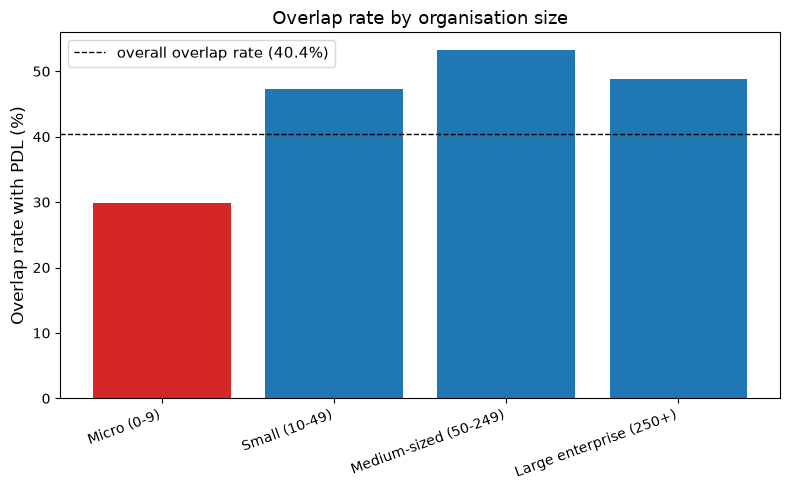

In [21]:
size_order = ['Micro (0-9)', 'Small (10-49)', 'Medium-sized (50-249)', 'Large enterprise (250+)']

size_overlap = goi_df.groupby('organization_size')['in_pdl'].agg(['mean', 'count'])
size_overlap['mean'] = 100 * size_overlap['mean']
size_overlap = size_overlap.reindex(size_order)

print('[Overlap rate by organisation size]')
print(size_overlap.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#1f77b4' if v >= 40.43 else '#d62728' for v in size_overlap['mean']]
ax.bar(size_overlap.index, size_overlap['mean'], color=colors)
ax.axhline(40.43, color='black', linestyle='--', linewidth=1, label='overall overlap rate (40.4%)')
ax.set_ylabel('Overlap rate with PDL (%)', fontsize=12)
ax.set_title('Overlap rate by organisation size', fontsize=13)
ax.set_xticklabels(size_overlap.index, rotation=20, ha='right', fontsize=10)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'overlap_rate_by_size.png', dpi=150)
plt.show()

## 12 · Save Consolidated Summary

Everything the slide deck needs, in one file.

In [22]:
summary = {
    'goi_sample_size': len(goi_df),
    'pdl_total_rows': pdl_total_rows,
    'pdl_parse_errors': pdl_parse_errors,
    'goi_unique_domains': len(goi_domains),
    'pdl_unique_domains': len(pdl_domains),
    'overlap_domain_count': len(overlap),
    'overlap_pct_of_goi_sample': round(overlap_pct_of_goi, 2),
    'overlap_pct_of_pdl': round(overlap_pct_of_pdl, 2),
    'goi_distinct_countries': len(goi_country_counts),
    'pdl_distinct_countries': len(pdl_country_counts),
    'goi_top_country_share_pct': {k: round(v, 2) for k, v in goi_country_share.items()},
    'pdl_top_country_share_pct': {k: round(v, 2) for k, v in pdl_country_share.items()},
    'pdl_has_description_field': pdl_has_description_field,
    'goi_size_buckets': dict(goi_size_counts),
    'pdl_size_buckets': dict(pdl_size_counts.most_common(10)),
    'goi_top_nace_sections': dict(goi_nace_counts.most_common(10)),
    'pdl_top_industry_labels': dict(pdl_industry_counts.most_common(10)),
    'overlap_rate_by_country_pct': {k: round(v, 2) for k, v in country_overlap['mean'].to_dict().items()},
    'overlap_rate_by_nace_pct': {k: round(v, 2) for k, v in nace_overlap['mean'].to_dict().items()},
    'overlap_rate_by_size_pct': {k: round(v, 2) for k, v in size_overlap['mean'].to_dict().items()},
}

with open(RESULT_DIR / 'comparison_summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print(f'[Save] Written to {RESULT_DIR / "comparison_summary.json"}')
print(json.dumps(summary, indent=2, ensure_ascii=False))

[Save] Written to result/comparison_summary.json
{
  "goi_sample_size": 300000,
  "pdl_total_rows": 35828989,
  "pdl_parse_errors": 0,
  "goi_unique_domains": 300000,
  "pdl_unique_domains": 23079155,
  "overlap_domain_count": 121300,
  "overlap_pct_of_goi_sample": 40.43,
  "overlap_pct_of_pdl": 0.53,
  "goi_distinct_countries": 198,
  "pdl_distinct_countries": 249,
  "goi_top_country_share_pct": {
    "United States": 24.88,
    "Germany": 10.61,
    "United Kingdom": 6.58,
    "China": 4.47,
    "Netherlands": 4.4,
    "Australia": 3.98,
    "Italy": 3.66,
    "Japan": 3.51,
    "France": 3.36,
    "Brazil": 3.01,
    "Canada": 2.23,
    "Spain": 2.22,
    "Russia": 2.19,
    "Poland": 2.01,
    "Czechia": 1.6
  },
  "pdl_top_country_share_pct": {
    "United States": 28.57,
    "United Kingdom": 9.93,
    "India": 6.71,
    "France": 6.65,
    "Brazil": 5.53,
    "Spain": 3.94,
    "China": 3.92,
    "Germany": 3.67,
    "Canada": 2.82,
    "Australia": 2.57,
    "Netherlands": 2.43